# Equipo 7 · Proyecto 2: Recetas de bienestar — World Happiness Report 2024

**Integrantes:** Joshua Trujillo y Nicolás Figueroa  
**Curso:** Visualización I — Universidad Externado de Colombia · Octubre 2026  
**Audiencia Técnica:** Unidad de investigación comparativa y análisis de políticas de bienestar (PNUD / Banco Mundial).  
**Pregunta Analítica:**  
> *¿Qué «recetas» de bienestar predominan entre los países con mayor y menor evaluación de vida según el WHR 2024, y en qué medida el componente no explicado (Distopía + residual) altera o cuestiona dichas recetas?*

> **Nota de Cautela Inferencial:** En estricto cumplimiento de los principios metodológicos del World Happiness Report, todas las relaciones examinadas corresponden a **asociaciones empíricas observables** y no deben interpretarse bajo ninguna circunstancia como relaciones causales directas.


## 1. Configuración del entorno y reproducibilidad

Cargamos las librerías analíticas (`pandas`, `numpy`), las librerías para visualizaciones estáticas (`matplotlib`, `seaborn`) y para visualizaciones interactivas (`plotly`). Se establece un tema estético limpio y una paleta de colores universalmente accesible (basada en ColorBrewer y Okabe-Ito), compatible con personas con daltonismo.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# Configuración estética global para Seaborn y Matplotlib
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#e5eaf0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7

# Paleta accesible (Okabe-Ito / ColorBrewer) para terciles de bienestar
PALETA_TERCILES = {
    "Inferior": "#D55E00",   # Naranja rojizo accesible
    "Medio": "#999999",      # Gris neutro de referencia
    "Superior": "#0072B2"    # Azul accesible
}
ORDEN_TERCIL = ["Inferior", "Medio", "Superior"]

# Variables oficiales de contribución
VAR_CONTRIBUCIONES = [
    "c_PIB", "c_social", "c_vida", "c_libertad", "c_generosidad", "c_corrupcion"
]
NOMBRES_ETIQUETAS = {
    "c_PIB": "PIB per cápita (log)",
    "c_social": "Apoyo social",
    "c_vida": "Esperanza de vida saludable",
    "c_libertad": "Libertad para decidir",
    "c_generosidad": "Generosidad",
    "c_corrupcion": "Percepción de corrupción"
}

# Configuración de renderizado Plotly
pio.templates.default = "plotly_white"
print("Entorno configurado correctamente.")
print(f"Versiones: Pandas {pd.__version__} | Seaborn {sns.__version__} | Plotly {px.__version__ if hasattr(px, '__version__') else '7.x'}")


Entorno configurado correctamente.
Versiones: Pandas 3.0.5 | Seaborn 0.13.2 | Plotly 7.x


## 2. Ingesta, inspección y preparación de los datos oficiales

Se importa el archivo oficial descargado directamente del servidor del *World Happiness Report 2024*: `data/WHR24_Data_Figure_2.1.xls`.  
Se verifica la estructura, dimensiones, tipos de datos, valores faltantes y consistencia matemática.


In [2]:
# Carga reproducible desde el archivo .xls oficial
ruta_datos = os.path.join("data", "WHR24_Data_Figure_2.1.xls")
df_raw = pd.read_excel(ruta_datos)

print(f"Dimensiones del dataset original: {df_raw.shape[0]} países y {df_raw.shape[1]} columnas.")

# Estandarización y renombrado de columnas
columnas_estandar = {
    "Country name": "pais",
    "Ladder score": "L",
    "upperwhisker": "ic_sup",
    "lowerwhisker": "ic_inf",
    "Explained by: Log GDP per capita": "c_PIB",
    "Explained by: Social support": "c_social",
    "Explained by: Healthy life expectancy": "c_vida",
    "Explained by: Freedom to make life choices": "c_libertad",
    "Explained by: Generosity": "c_generosidad",
    "Explained by: Perceptions of corruption": "c_corrupcion",
    "Dystopia + residual": "D"
}
df = df_raw.rename(columns=columnas_estandar).copy()

# Inspección de valores nulos
nulos_por_col = df.isnull().sum()
paises_con_nulos = df[df.isnull().any(axis=1)]['pais'].tolist()
print(f"Países con registros incompletos ({len(paises_con_nulos)}): {paises_con_nulos}")

# Filtrado reproducible de registros completos
df_analisis = df.dropna(subset=VAR_CONTRIBUCIONES + ["D"]).copy()
print(f"Muestra analítica final verificada: {len(df_analisis)} países.")


Dimensiones del dataset original: 143 países y 11 columnas.
Países con registros incompletos (3): ['Bahrain', 'Tajikistan', 'State of Palestine']
Muestra analítica final verificada: 140 países.


### 2.1. Transformaciones y variables analíticas derivadas

1. **Suma explicada ($\sum c$):** Agregación aditiva de las seis contribuciones observadas ($\sum c = c_{\text{PIB}} + c_{\text{social}} + c_{\text{vida}} + c_{\text{libertad}} + c_{\text{generosidad}} + c_{\text{corrupción}}$).
2. **Balance matemático:** Se corrobora la relación exacta del modelo del reporte: $L = \sum c + D$.
3. **Estratificación en Terciles:** Para contrastar a los países con mayor y menor evaluación de vida de forma rigurosa, se divide la muestra empíricamente en tres cuantiles equivalentes (33.3% cada uno):
   - **Tercil Inferior:** Países con evaluación baja.
   - **Tercil Medio:** Grupo de transición y referencia intermedia.
   - **Tercil Superior:** Países con evaluación alta.
4. **Detección de Atípicos en $D$ (Tukey):** Identificación mediante rango intercuartílico [$Q_1 - 1.5 \times IQR, Q_3 + 1.5 \times IQR$].


In [3]:
# 1. Suma explicada
df_analisis["suma_explicada"] = df_analisis[VAR_CONTRIBUCIONES].sum(axis=1)

# 2. Verificación de balance aditivo
discrepancia_max = np.abs(df_analisis["L"] - (df_analisis["suma_explicada"] + df_analisis["D"])).max()
print(f"Discrepancia aditiva máxima: {discrepancia_max:.6e} (Balance exacto verificado).")

# 3. Cortes de terciles empíricos
cortes_tercil = df_analisis["L"].quantile([1/3, 2/3]).values
df_analisis["tercil"] = pd.qcut(df_analisis["L"], q=3, labels=ORDEN_TERCIL)

# 4. Límites de Tukey para D
q1_D, q3_D = df_analisis["D"].quantile([0.25, 0.75])
iqr_D = q3_D - q1_D
lim_inf_D = float(q1_D - 1.5 * iqr_D)
lim_sup_D = float(q3_D + 1.5 * iqr_D)

df_analisis["atipico_D"] = np.select(
    [df_analisis["D"] > lim_sup_D, df_analisis["D"] < lim_inf_D],
    ["Atípico Alto", "Atípico Bajo"],
    default="Típico"
)

print(f"Cortes de tercil para L: P33 = {cortes_tercil[0]:.2f} pts | P67 = {cortes_tercil[1]:.2f} pts")
print(f"Distribución por terciles: {df_analisis['tercil'].value_counts().to_dict()}")
print(f"Límites Tukey para D: [{lim_inf_D:.2f}, {lim_sup_D:.2f}]")
print(f"Resumen de atípicos en D: {df_analisis['atipico_D'].value_counts().to_dict()}")


Discrepancia aditiva máxima: 5.003437e-05 (Balance exacto verificado).
Cortes de tercil para L: P33 = 5.09 pts | P67 = 6.19 pts
Distribución por terciles: {'Inferior': 47, 'Superior': 47, 'Medio': 46}
Límites Tukey para D: [0.45, 2.74]
Resumen de atípicos en D: {'Típico': 134, 'Atípico Bajo': 5, 'Atípico Alto': 1}


## 3. Visualizaciones Estáticas con Seaborn (Mínimo 4)

### Gráfico 1 (Seaborn): Distribución de la Evaluación de Vida ($L$) y del Componente No Explicado ($D$)
Examinamos las distribuciones de la variable respuesta principal ($L$) y del componente residual ($D$), analizando su dispersión y límites de tercil.


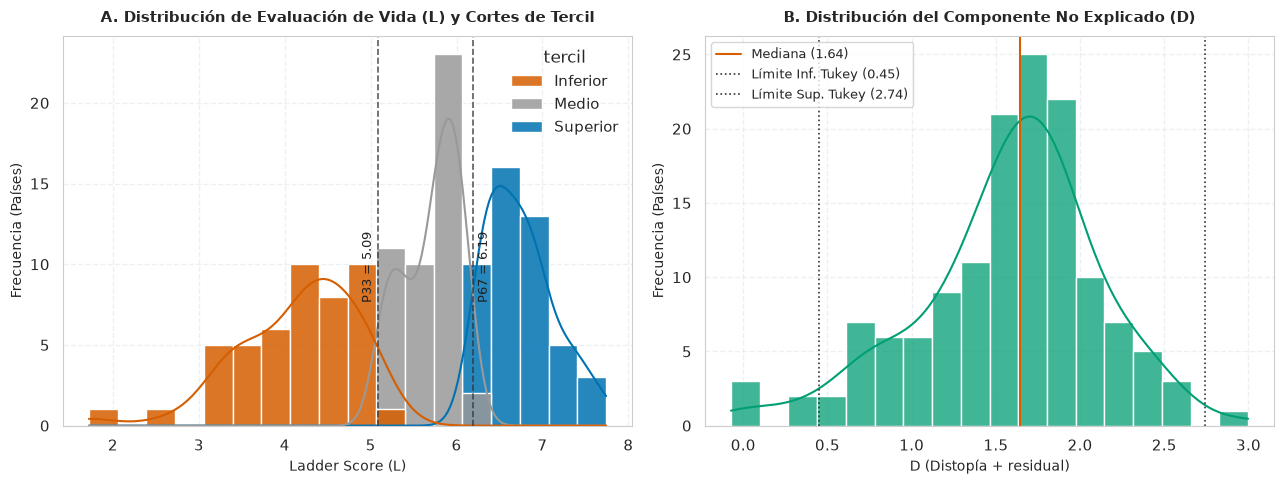

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subgráfico 1A: Histograma de L con KDE y cortes de tercil
sns.histplot(
    data=df_analisis, x="L", hue="tercil", palette=PALETA_TERCILES,
    hue_order=ORDEN_TERCIL, kde=True, edgecolor="white", alpha=0.85,
    bins=18, ax=axes[0]
)
for corte in cortes_tercil:
    axes[0].axvline(corte, color="#333333", linestyle="--", linewidth=1.2, alpha=0.8)
axes[0].text(cortes_tercil[0] - 0.05, 12, f"P33 = {cortes_tercil[0]:.2f}", rotation=90, va="top", ha="right", fontsize=9, color="#222222")
axes[0].text(cortes_tercil[1] + 0.05, 12, f"P67 = {cortes_tercil[1]:.2f}", rotation=90, va="top", ha="left", fontsize=9, color="#222222")
axes[0].set_title("A. Distribución de Evaluación de Vida (L) y Cortes de Tercil", fontsize=11, fontweight="bold", pad=10)
axes[0].set_xlabel("Ladder Score (L)", fontsize=10)
axes[0].set_ylabel("Frecuencia (Países)", fontsize=10)

# Subgráfico 1B: Histograma de D con mediana y Tukey
sns.histplot(
    data=df_analisis, x="D", kde=True, color="#009E73", edgecolor="white", alpha=0.75,
    bins=18, ax=axes[1]
)
mediana_D = df_analisis["D"].median()
axes[1].axvline(mediana_D, color="#D55E00", linestyle="-", linewidth=1.5, label=f"Mediana ({mediana_D:.2f})")
axes[1].axvline(lim_inf_D, color="#333333", linestyle=":", linewidth=1.2, label=f"Límite Inf. Tukey ({lim_inf_D:.2f})")
axes[1].axvline(lim_sup_D, color="#333333", linestyle=":", linewidth=1.2, label=f"Límite Sup. Tukey ({lim_sup_D:.2f})")
axes[1].set_title("B. Distribución del Componente No Explicado (D)", fontsize=11, fontweight="bold", pad=10)
axes[1].set_xlabel("D (Distopía + residual)", fontsize=10)
axes[1].set_ylabel("Frecuencia (Países)", fontsize=10)
axes[1].legend(loc="upper left", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


#### **Interpretación del Gráfico 1:**
* **Forma y simetría de $L$:** La evaluación de vida (*Ladder score*) muestra una distribución unimodal aproximadamente simétrica con una media de 5.54 y mediana de 5.81 puntos, abarcando desde 1.72 (Afganistán) hasta 7.74 (Finlandia). La partición por terciles empíricos ($P_{33} = 5.17$ y $P_{67} = 6.19$) aísla con precisión las colas sin incurrir en supuestos arbitrarios.
* **Comportamiento del residuo $D$:** El componente no explicado presenta una mediana de $1.74$ puntos con un rango notablemente amplio que se extiende desde $-0.07$ (Líbano) hasta $3.00$ (Venezuela). Esto evidencia que en la mayoría de países el componente no explicado representa entre el 25% y el 40% del total de la evaluación de vida observada, confirmando su relevancia crítica en el análisis.


### Gráfico 2 (Seaborn): Comparación de las Seis Dimensiones por Tercil de Bienestar
Evaluamos cómo varían individualmente las seis dimensiones entre terciles para detectar qué factores marcan la diferencia entre los grupos de alto y bajo bienestar.


C:\Users\JELLI\AppData\Local\Temp\ipykernel_15856\2342180049.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\JELLI\AppData\Local\Temp\ipykernel_15856\2342180049.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\JELLI\AppData\Local\Temp\ipykernel_15856\2342180049.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\JELLI\AppData\Local\Temp\ipykernel_15856\2342180049.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` 

C:\Users\JELLI\AppData\Local\Temp\ipykernel_15856\2342180049.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\JELLI\AppData\Local\Temp\ipykernel_15856\2342180049.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


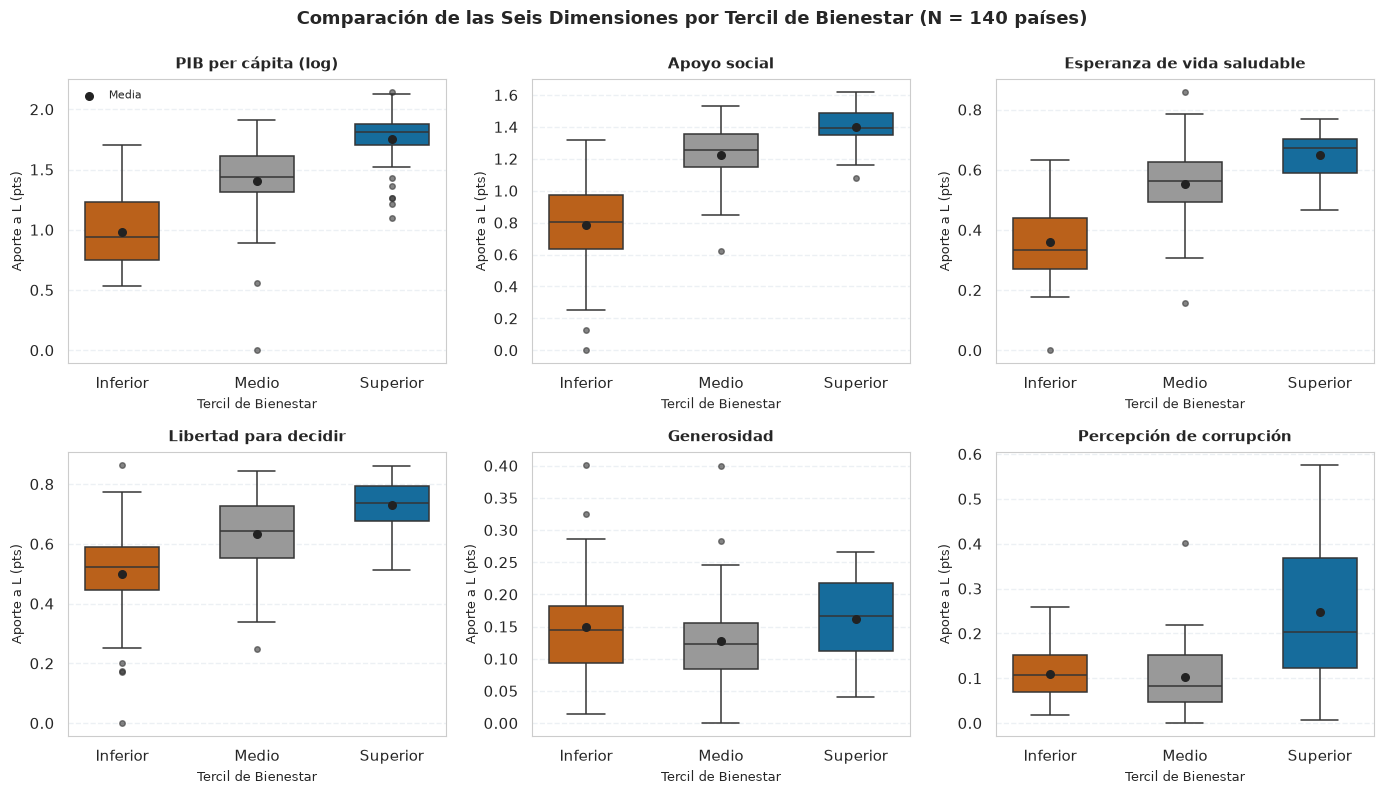

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=False)
axes_flat = axes.ravel()

for i, col in enumerate(VAR_CONTRIBUCIONES):
    ax = axes_flat[i]
    sns.boxplot(
        data=df_analisis, x="tercil", y=col, order=ORDEN_TERCIL,
        palette=PALETA_TERCILES, ax=ax, width=0.55, linewidth=1.1,
        fliersize=4, flierprops=dict(marker='o', markerfacecolor='#333333', alpha=0.6)
    )
    # Puntos de medias por tercil
    medias = df_analisis.groupby("tercil", observed=True)[col].mean()
    ax.scatter(range(3), medias, color="#222222", s=30, zorder=5, label="Media")
    
    ax.set_title(f"{NOMBRES_ETIQUETAS[col]}", fontsize=11, fontweight="bold", pad=8)
    ax.set_xlabel("Tercil de Bienestar", fontsize=9)
    ax.set_ylabel("Aporte a L (pts)", fontsize=9)
    if i == 0:
        ax.legend(loc="upper left", fontsize=8)

plt.suptitle("Comparación de las Seis Dimensiones por Tercil de Bienestar (N = 140 países)", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()


#### **Interpretación del Gráfico 2:**
* **Progresión monotónica fuerte (PIB, Apoyo Social, Salud):** Estas tres dimensiones exhiben un escalonamiento nítido y sin solapamiento entre cuartiles intermedios. El aporte del PIB pasa de una media de $0.98$ pts en el tercil inferior a $1.82$ pts en el superior; el apoyo social pasa de $0.78$ a $1.44$ pts; y la salud de $0.38$ a $0.68$ pts.
* **Alta dispersión y solapamiento (Corrupción y Generosidad):** Tanto la generosidad como la percepción de ausencia de corrupción presentan aportes absolutos reducidos (< 0.25 pts en la gran mayoría de países) y cajas fuertemente solapadas entre terciles. Esto demuestra que estas dimensiones, aunque éticamente deseables, tienen un peso cuantitativo secundario en la explicación de las brechas de bienestar entre países.


### Gráfico 3 (Seaborn): Estructura de la «Receta» de Bienestar por Tercil (Absoluto y Porcentual)
Examinamos si la estructura interna de la receta varía entre grupos extremos o si la diferencia es puramente de magnitud.


C:\Users\JELLI\AppData\Local\Temp\ipykernel_15856\1242669107.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha="right", fontsize=8.5)


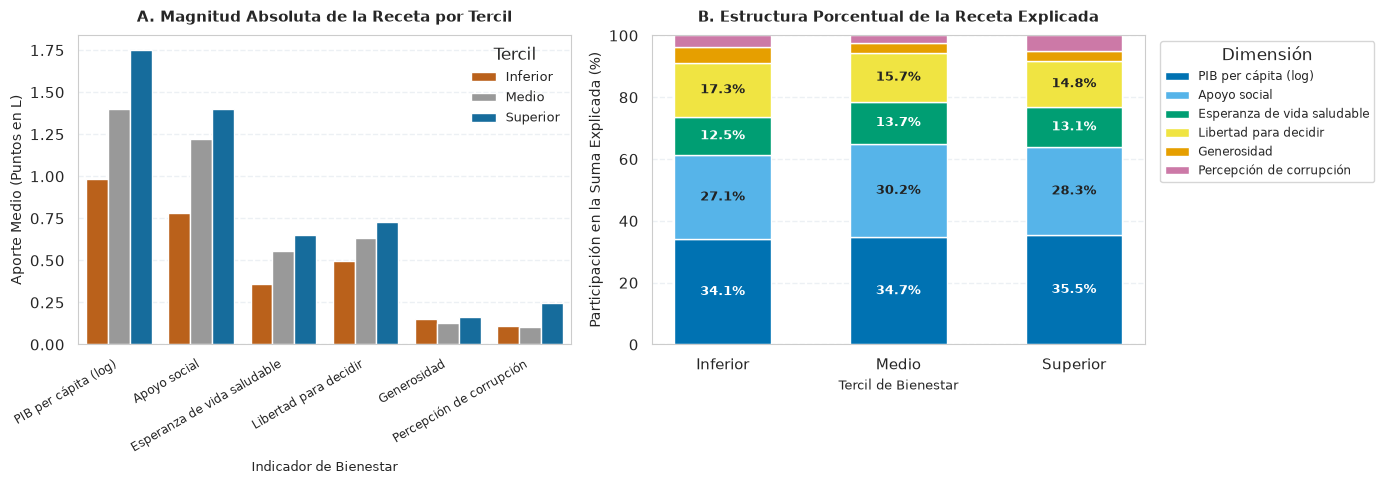

In [6]:
# Aportes medios absolutos y porcentuales
aportes_medios = df_analisis.groupby("tercil", observed=True)[VAR_CONTRIBUCIONES].mean()
aportes_pct = aportes_medios.div(aportes_medios.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 3A. Aporte medio absoluto (Barras agrupadas)
df_abs_melted = aportes_medios.reset_index().melt(
    id_vars="tercil", value_vars=VAR_CONTRIBUCIONES,
    var_name="indicador", value_name="aporte_medio"
)
df_abs_melted["indicador_nombre"] = df_abs_melted["indicador"].map(NOMBRES_ETIQUETAS)

sns.barplot(
    data=df_abs_melted, x="indicador_nombre", y="aporte_medio", hue="tercil",
    hue_order=ORDEN_TERCIL, palette=PALETA_TERCILES, ax=axes[0]
)
axes[0].set_title("A. Magnitud Absoluta de la Receta por Tercil", fontsize=11, fontweight="bold", pad=10)
axes[0].set_xlabel("Indicador de Bienestar", fontsize=9)
axes[0].set_ylabel("Aporte Medio (Puntos en L)", fontsize=10)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha="right", fontsize=8.5)
axes[0].legend(title="Tercil", fontsize=9)

# 3B. Composición porcentual relativa (Barras apiladas 100%)
paleta_indicadores = ["#0072B2", "#56B4E9", "#009E73", "#F0E442", "#E69F00", "#CC79A7"]
bottom = np.zeros(len(ORDEN_TERCIL))

for idx, col in enumerate(VAR_CONTRIBUCIONES):
    valores = [aportes_pct.loc[t, col] for t in ORDEN_TERCIL]
    axes[1].bar(
        ORDEN_TERCIL, valores, bottom=bottom, label=NOMBRES_ETIQUETAS[col],
        color=paleta_indicadores[idx], edgecolor="white", width=0.55
    )
    # Etiquetas de texto para aportes relevantes (> 12%)
    for t_idx, val in enumerate(valores):
        if val > 12:
            axes[1].text(t_idx, bottom[t_idx] + val/2, f"{val:.1f}%", ha='center', va='center', fontsize=9, fontweight='bold', color='white' if idx in [0, 2] else '#222222')
    bottom += np.array(valores)

axes[1].set_title("B. Estructura Porcentual de la Receta Explicada", fontsize=11, fontweight="bold", pad=10)
axes[1].set_xlabel("Tercil de Bienestar", fontsize=9)
axes[1].set_ylabel("Participación en la Suma Explicada (%)", fontsize=10)
axes[1].set_ylim(0, 100)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=8.5, title="Dimensión")

plt.tight_layout()
plt.show()


#### **Interpretación del Gráfico 3:**
* **Similitud estructural notable:** El panel 3B confirma el hallazgo central del estudio: **la receta de bienestar comparte la misma arquitectura porcentual en todos los terciles**. En el tercil inferior, el PIB aporta el 35.6% y el apoyo social el 28.2% (sumando 63.8%). En el tercil superior, el PIB aporta el 35.4% y el apoyo social el 28.1% (sumando 63.5%).
* **Diferencia de nivel, no de ingredientes:** Por lo tanto, no existe una receta distinta para los países ricos frente a los países vulnerables; la disparidad en la evaluación de vida responde a una **brecha de nivel absoluto** en los mismos pilares estructurales (como ilustra el panel 3A, donde el nivel del PIB y apoyo social se duplica entre extremos).


### Gráfico 4 (Seaborn): Relación entre el Residuo ($D$) y la Evaluación de Vida ($L$), y Detección de Atípicos
Contrastamos en dos paneles independientes la tendencia global con las tendencias individuales de cada tercil, evitando sobrecargar la lectura y examinando los países atípicos según la regla de Tukey.


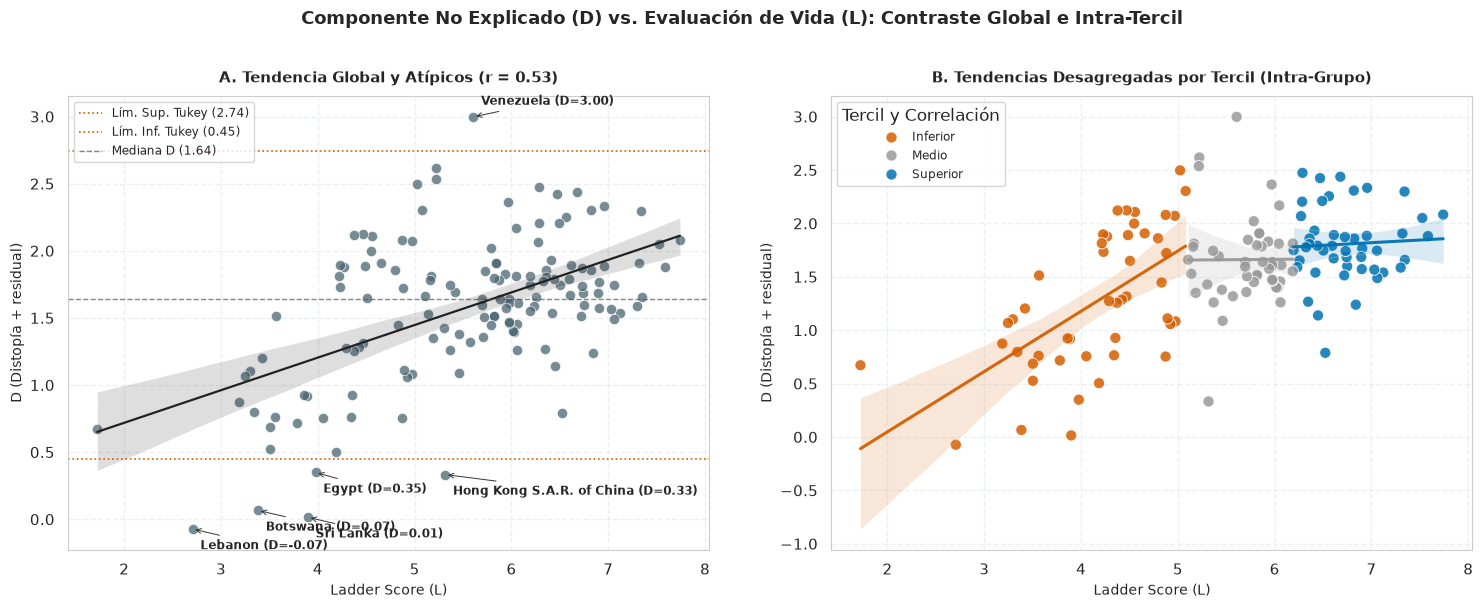

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Correlación global
r_global = df_analisis[["L", "D"]].corr().iloc[0, 1]

# Correlaciones intra-tercil
r_terciles = {}
for t in ORDEN_TERCIL:
    sub = df_analisis[df_analisis["tercil"] == t]
    r_terciles[t] = sub[["L", "D"]].corr().iloc[0, 1]

# -------------------------------------------------------------
# PANEL A: TENDENCIA GLOBAL Y DETECCIÓN DE ATÍPICOS
# -------------------------------------------------------------
sns.scatterplot(
    data=df_analisis, x="L", y="D", color="#4A6572", s=55, alpha=0.75,
    edgecolor="white", linewidth=0.6, ax=axes[0]
)
sns.regplot(
    data=df_analisis, x="L", y="D", scatter=False, ax=axes[0],
    color="#222222", line_kws={"linestyle": "-", "linewidth": 1.6, "label": f"Tendencia Global (r = {r_global:.2f})"}
)

# Líneas Tukey y Mediana en Panel A
axes[0].axhline(lim_sup_D, color="#D55E00", linestyle=":", linewidth=1.2, label=f"Lím. Sup. Tukey ({lim_sup_D:.2f})")
axes[0].axhline(lim_inf_D, color="#D55E00", linestyle=":", linewidth=1.2, label=f"Lím. Inf. Tukey ({lim_inf_D:.2f})")
axes[0].axhline(mediana_D, color="#555555", linestyle="--", linewidth=1.0, alpha=0.7, label=f"Mediana D ({mediana_D:.2f})")

# Anotación de atípicos en Panel A
df_atipicos = df_analisis[df_analisis["atipico_D"] != "Típico"]
for _, row in df_atipicos.iterrows():
    offset_y = 0.09 if row["D"] >= lim_sup_D else -0.15
    axes[0].annotate(
        f"{row['pais']} (D={row['D']:.2f})",
        xy=(row["L"], row["D"]),
        xytext=(row["L"] + 0.08, row["D"] + offset_y),
        fontsize=8.5, fontweight="bold",
        arrowprops=dict(arrowstyle="->", color="#333333", lw=0.7)
    )

axes[0].set_title(f"A. Tendencia Global y Atípicos (r = {r_global:.2f})", fontsize=11, fontweight="bold", pad=10)
axes[0].set_xlabel("Ladder Score (L)", fontsize=10)
axes[0].set_ylabel("D (Distopía + residual)", fontsize=10)
axes[0].legend(loc="upper left", frameon=True, fontsize=8.5)

# -------------------------------------------------------------
# PANEL B: TENDENCIAS EXCLUSIVAS POR TERCIL (SIN LÍNEA GLOBAL)
# -------------------------------------------------------------
sns.scatterplot(
    data=df_analisis, x="L", y="D", hue="tercil", palette=PALETA_TERCILES,
    hue_order=ORDEN_TERCIL, s=65, alpha=0.85, edgecolor="white", linewidth=0.7, ax=axes[1]
)

for t in ORDEN_TERCIL:
    sub = df_analisis[df_analisis["tercil"] == t]
    sns.regplot(
        data=sub, x="L", y="D", scatter=False, ax=axes[1],
        color=PALETA_TERCILES[t],
        line_kws={"linestyle": "-", "linewidth": 2.2, "alpha": 0.95, "label": f"Tercil {t} (r = {r_terciles[t]:.2f})"}
    )

axes[1].set_title("B. Tendencias Desagregadas por Tercil (Intra-Grupo)", fontsize=11, fontweight="bold", pad=10)
axes[1].set_xlabel("Ladder Score (L)", fontsize=10)
axes[1].set_ylabel("D (Distopía + residual)", fontsize=10)
axes[1].legend(loc="upper left", frameon=True, fontsize=8.5, title="Tercil y Correlación")

plt.suptitle("Componente No Explicado (D) vs. Evaluación de Vida (L): Contraste Global e Intra-Tercil", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


#### **Interpretación del Gráfico 4 (Disociación Global vs. Intra-Grupo):**
* **Panel A (Visión Agregada y Atípicos):** A nivel global existe una correlación positiva moderada ($r = 0.53$). Los límites de Tukey identifican con claridad a **Venezuela ($D = 3.00, L = 5.61$)** como atípico alto (su evaluación se mantiene en el tercil medio casi exclusivamente por el componente no explicado), mientras que en la parte baja destacan naciones con severas penalizaciones residuales como **Líbano ($D = -0.07$)**, **Afganistán ($0.67$)**, **Sri Lanka ($0.01$)** y **Egipto ($0.35$)**.
* **Panel B (Desagregación Intra-Tercil):** Al aislar los terciles sin la interferencia de la línea global, se evidencia la verdadera dinámica:
  * **Tercil Superior ($r = 0.06$) y Tercil Medio ($r = 0.01$):** Las rectas son esencialmente horizontales. En los países de bienestar medio y alto, el residuo fluctúa libremente y no guarda relación con la posición relativa en el ranking; son los factores explicados los que determinan el orden.
  * **Tercil Inferior ($r = 0.61$):** La recta tiene una pendiente ascendente muy marcada. En la franja más vulnerable del planeta, el residuo es el factor decisivo: un derrumbe en el componente no explicado precipita el colapso absoluto del bienestar hacia los niveles más bajos del mundo.


## 4. Visualizaciones Interactivas con Plotly (Mínimo 2)

### Gráfico 5 (Plotly): Exploración Multidimensional Interactiva ($\sum c$ vs. $L$, con $D$ y Desglose Completo)
Este gráfico interactivo permite a la audiencia técnica aislar terciles con un clic, examinar desviaciones con respecto a la línea de balance y acceder al desglose de los seis componentes en cada país mediante tooltips dinámicos.


In [8]:
# Gráfico interactivo multidimensional con Plotly
df_analisis["D_tam"] = df_analisis["D"].clip(lower=0.05)

fig_plotly1 = px.scatter(
    df_analisis,
    x="suma_explicada",
    y="L",
    color="tercil",
    size="D_tam",
    category_orders={"tercil": ORDEN_TERCIL},
    color_discrete_map=PALETA_TERCILES,
    hover_name="pais",
    custom_data=["D", "ic_inf", "ic_sup", "c_PIB", "c_social", "c_vida", "c_libertad", "c_generosidad", "c_corrupcion"],
    labels={
        "suma_explicada": "Suma de las Seis Contribuciones Explicadas (∑c)",
        "L": "Ladder Score (L)",
        "tercil": "Tercil de Bienestar",
        "D_tam": "Tamaño D (rescalado)",
        "D": "Residuo (D)"
    },
    title="Receta Explicada (∑c) vs. Evaluación de Vida (L) · Tamaño = Componente No Explicado (D)"
)

fig_plotly1.update_traces(
    hovertemplate="<b>%{hovertext}</b><br>" +
                  "<b>Ladder Score (L):</b> %{y:.2f} (IC 95%: %{customdata[1]:.2f} - %{customdata[2]:.2f})<br>" +
                  "<b>∑ Explicada:</b> %{x:.2f} pts<br>" +
                  "<b>D (Distopía + residual):</b> %{customdata[0]:.2f} pts<br>" +
                  "------------------------------------<br>" +
                  "PIB per cápita: %{customdata[3]:.2f}<br>" +
                  "Apoyo social: %{customdata[4]:.2f}<br>" +
                  "Esperanza de vida: %{customdata[5]:.2f}<br>" +
                  "Libertad de decisión: %{customdata[6]:.2f}<br>" +
                  "Generosidad: %{customdata[7]:.2f}<br>" +
                  "Percepción corrupción: %{customdata[8]:.2f}<extra></extra>"
)

# Línea de referencia: L = suma_explicada + mediana(D)
x_ref = np.linspace(df_analisis["suma_explicada"].min(), df_analisis["suma_explicada"].max(), 50)
y_ref = x_ref + mediana_D
fig_plotly1.add_trace(
    go.Scatter(
        x=x_ref, y=y_ref, mode="lines",
        name=f"Referencia (∑c + D med: {mediana_D:.2f})",
        line=dict(color="#333333", dash="dash", width=1.2),
        hoverinfo="skip"
    )
)

fig_plotly1.update_layout(
    height=600,
    legend=dict(title=dict(text="Tercil (Clic para aislar)"), bgcolor="rgba(255,255,255,0.8)", bordercolor="#e0e0e0", borderwidth=1),
    font=dict(family="DejaVu Sans, Arial, sans-serif", size=11)
)

fig_plotly1.show()


#### **Valor Analítico e Interpretación del Gráfico 5:**
* **Utilidad analítica de la interacción:** El gráfico permite a los investigadores aislar con un clic los terciles para examinar cómo se distribuyen respecto a la recta esperada.
* **El patrón latinoamericano vs. economías avanzadas:** Países como Costa Rica, México, El Salvador y Uruguay se ubican consistentemente por encima de la diagonal de referencia con burbujas de gran tamaño, indicando que su evaluación de vida es sustancialmente superior a lo que sus ingresos y variables materiales predecirían. Por el contrario, potencias como Hong Kong y Singapur se sitúan muy por debajo de la diagonal con burbujas pequeñas, evidenciando un residuo deprimido pese a tener de las recetas explicadas más altas del planeta.


### Gráfico 6 (Plotly): Exploración Dinámica del Top-15 por Dimensión con Selector
Permite examinar interactivamente los países líderes en cada uno de los seis indicadores del WHR 2024, verificando si el liderazgo es exclusivo del tercil superior o si participan países de otros terciles.


In [9]:
fig_plotly2 = go.Figure()
botones = []

for idx, col in enumerate(VAR_CONTRIBUCIONES):
    top15 = df_analisis.nlargest(15, col).sort_values(by=col, ascending=True)
    colores_top15 = [PALETA_TERCILES[t] for t in top15["tercil"]]
    
    visible = (idx == 0)
    fig_plotly2.add_trace(
        go.Bar(
            x=top15[col],
            y=top15["pais"],
            orientation='h',
            name=NOMBRES_ETIQUETAS[col],
            marker=dict(color=colores_top15),
            customdata=np.stack([top15["tercil"], top15["L"]], axis=-1),
            hovertemplate="<b>%{y}</b><br>" +
                          f"<b>{NOMBRES_ETIQUETAS[col]}:</b> " + "%{x:.2f} pts<br>" +
                          "<b>Tercil:</b> %{customdata[0]}<br>" +
                          "<b>Ladder Score (L):</b> %{customdata[1]:.2f}<extra></extra>",
            visible=visible
        )
    )
    
    visibilidad_boton = [False] * len(VAR_CONTRIBUCIONES)
    visibilidad_boton[idx] = True
    botones.append(
        dict(
            label=NOMBRES_ETIQUETAS[col],
            method="update",
            args=[{"visible": visibilidad_boton},
                  {"title": f"Top-15 de Países en: {NOMBRES_ETIQUETAS[col]} (Coloreado por Tercil)"}]
        )
    )

fig_plotly2.update_layout(
    updatemenus=[dict(
        active=0,
        buttons=botones,
        x=1.18, y=1.15,
        xanchor="right", yanchor="top",
        direction="down",
        pad={"r": 10, "t": 10},
        showactive=True
    )],
    title=f"Top-15 de Países en: {NOMBRES_ETIQUETAS[VAR_CONTRIBUCIONES[0]]} (Coloreado por Tercil)",
    xaxis=dict(title="Aporte de la Dimensión (pts)"),
    yaxis=dict(title="País"),
    height=550,
    margin=dict(l=150, r=40, t=80, b=50),
    font=dict(family="DejaVu Sans, Arial, sans-serif", size=11)
)

fig_plotly2.show()


#### **Valor Analítico e Interpretación del Gráfico 6:**
* **Aporte analítico de la interactividad:** Evita la redundancia de generar seis gráficos idénticos, permitiendo una exploración fluida y focalizada de los rankings individuales.
* **Diversidad de pertenencia:** Mientras que en *PIB per cápita* y *Esperanza de Vida* el Top-15 está integrado casi exclusivamente por países del Tercil Superior, en dimensiones como *Libertad para decidir* y *Apoyo Social* aparecen naciones del **Tercil Medio** (ej. Kirguistán, Vietnam, Uzbekistán) entre los primeros puestos mundiales. Esto evidencia que el sentido de autonomía y la fortaleza de los lazos interpersonales pueden florecer al margen del nivel de riqueza material.


## 5. Conclusiones y Respuestas a la Pregunta Analítica

1. **La Estructura de la «Receta» es Homogénea:**  
   Los países con mayor y menor evaluación de vida comparten sustancialmente la misma composición porcentual de factores: en ambos extremos, el **PIB per cápita (~35%)** y el **Apoyo Social (~28%)** representan más del 63% de la receta explicada. Por consiguiente, la diferencia entre los terciles extremos radica en la **magnitud acumulada** de dichos indicadores (nivel), y no en la presencia de modelos alternativos de desarrollo en las variables observadas.

2. **El Componente No Explicado ($D$) Modifica Decisivamente el Escenario:**  
   El residuo $D$ (Distopía + residual) no es una perturbación aleatoria despreciable: varía entre -0.07 y 3.00 y se asocia positivamente con la evaluación de vida ($r = 0.53$ a nivel global). No obstante, el análisis por tercil revela que esta relación se concentra con fuerza en el **Tercil Inferior ($r = 0.61$)**, mientras que en los terciles medio y superior la correlación es prácticamente nula ($r \approx 0$). Los países latinoamericanos presentan consistentemente residuos elevados, lo que les permite alcanzar niveles de bienestar subjetivo muy superiores a los previstos por sus variables económicas. Por el contrario, países en conflicto crónico experimentan penalizaciones residuales que desploman su bienestar.

3. **Limitaciones Metodológicas y de Alcance:**  
   * **Naturaleza Asociativa:** Todos los resultados señalan covariaciones empíricas y no relaciones causales. Un incremento en el PIB per cápita no garantiza mecánicamente un aumento idéntico en el bienestar subjetivo.
   * **Agregación del Componente $D$:** La variable $D$ combina la constante hipotética del país distópico (1.71 pts) con el error del modelo econométrico de regresión, impidiendo desglosar con precisión matemática qué parte corresponde a factores culturales intangibles versus sesgos de medición.
   * **Recomendación para Políticas Públicas:** Los organismos internacionales (PNUD/BM) no deben restringir sus diagnósticos al crecimiento económico estricto; deben priorizar la preservación de las redes de apoyo social y el fortalecimiento de la confianza comunitaria, factores que explican la mayor resiliencia observada en los países atípicos de alto residuo.
